# Nonlinear regression: logistic growth with non-constant variance

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.optimize import least_squares
from scipy.stats import t

Second notebook about the `ChickWeight` data. In the first one we fitted a logistic growth curve to one chick. Now we use all the chicks of one diet: the chicks become more and more different as they grow, so the variance is not constant, and we have to model it to get sensible intervals.

In [2]:
dat = pd.read_csv('chick_weight.csv')
dat = dat.rename(columns={'Weight': 'weight'})
dat['Diet'] = dat['Diet'].astype('category')

alpha = 0.05

In [3]:
point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
pi_color    = '#cfe8f3'

Let's select just the diet 3

In [4]:
dat_example = dat.loc[dat['Diet'] == 3, ['weight', 'Time', 'Chick']].reset_index(drop=True)

Y = dat_example['weight'].to_numpy(dtype=float)
x = dat_example['Time'].to_numpy(dtype=float)
n = len(Y)
p = 3

times = np.sort(dat_example['Time'].unique()).astype(float)
print('Observations:', n, ' Chicks:', dat_example['Chick'].nunique())

Observations: 120  Chicks: 10


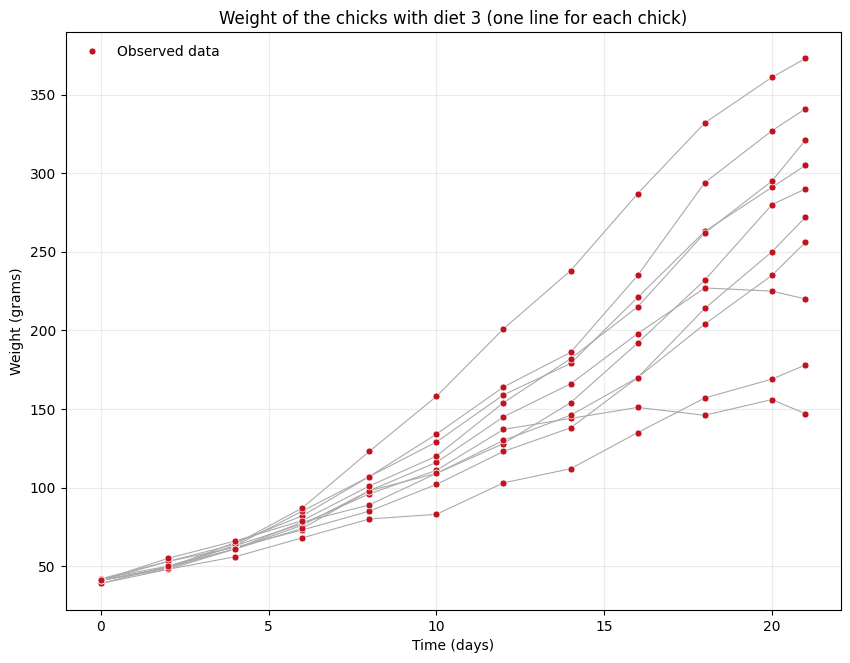

In [5]:
def plot_chicks(ax, lines=True):
    if lines:
        for chick, dat_chick in dat_example.groupby('Chick'):
            ax.plot(dat_chick['Time'], dat_chick['weight'], color='#aaaaaa', lw=0.8, zorder=1)
    ax.plot(x, Y, 'o', color=point_color, markersize=5, markeredgecolor='white', markeredgewidth=0.5,
            label='Observed data', zorder=3)
    ax.set_xlabel('Time (days)')
    ax.set_ylabel('Weight (grams)')
    ax.grid(True, alpha=0.25)

fig, ax = plt.subplots(figsize=(10, 7.5))
plot_chicks(ax)
ax.set_title('Weight of the chicks with diet 3 (one line for each chick)')
ax.legend(loc='upper left', frameon=False)

## The model and its derivatives

The same logistic growth curve of the first notebook, $f(t; M, r, b) = M/(1+e^{-r(t-b)})$.

In [6]:
def logistic_gowth(theta, t):
    return theta[0] / (1 + np.exp(- theta[1] * (t - theta[2])))

def F_1(t,M,r,b):
    return(1/(1+np.exp(-r*(t-b))))

def F_2(t,M,r,b):
    return((M*(t-b)*np.exp(-r*(t-b)))/(1+np.exp(-r*(t-b)))**2)

def F_3(t,M,r,b):
    return((-M*r*np.exp(-r*(t-b)))/(1+np.exp(-r*(t-b)))**2)

def gradient(t, theta):
    # One row for each time, one column for each parameter
    return np.vstack([F_1(t, *theta), F_2(t, *theta), F_3(t, *theta)]).T

def summary(theta, var_matrix, df):
    se = np.sqrt(np.diag(var_matrix))
    q_t = t.ppf(1-alpha/2, df)
    return pd.DataFrame({'estimate': theta, 'std. error': se, 't': theta/se,
                         'p-value': 2*(1-t.cdf(np.abs(theta/se), df)),
                         'lower': theta - q_t*se, 'upper': theta + q_t*se}, index=['M', 'r', 'b']).round(4)

## Ordinary nonlinear least squares

In [7]:
# Initialize
M0 = Y.max()
r0 = 0.1
b0 = 15
theta0 = [M0,r0,b0]

def fun(theta):
    return logistic_gowth(theta, x) - Y

log_growth = least_squares(fun, theta0)
theta_star = log_growth.x
F_matrix = log_growth.jac

hat_sigma2 = sum((log_growth.fun)**2)/(n-p)
var_matrix_params = hat_sigma2 * np.linalg.inv(F_matrix.T @ F_matrix)

print('sigma^2:', hat_sigma2)
summary(theta_star, var_matrix_params, n-p)

sigma^2: 1330.3693730701027


,estimate,std. error,t,p-value,lower,upper
M,466.1356,130.1502,3.5815,0.0005,208.3800,723.8913
r,0.1295,0.0217,5.9700,0.0000,0.0866,0.1725
b,18.3364,4.3881,4.1787,0.0001,9.6461,27.0267


Confidence and prediction intervals, with the delta method and assuming a constant variance.

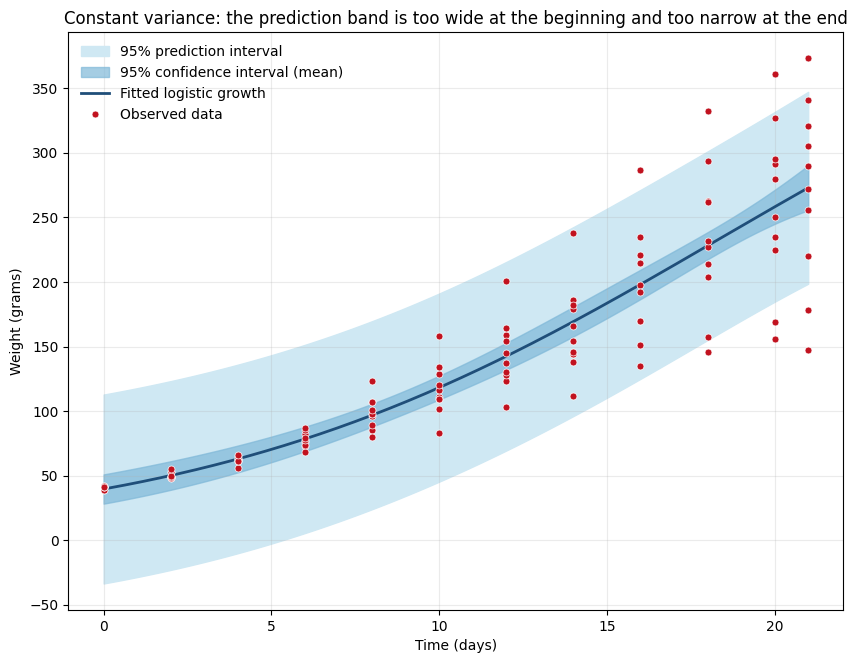

In [8]:
q_t = t.ppf(1-alpha/2, n-p)
ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'

x_grid = np.linspace(0, 21, 200)
fit = logistic_gowth(theta_star, x_grid)
F_grid = gradient(x_grid, theta_star)
sist_var = np.sum((F_grid @ var_matrix_params) * F_grid, axis=1)

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.fill_between(x_grid, fit - q_t*np.sqrt(hat_sigma2 + sist_var), fit + q_t*np.sqrt(hat_sigma2 + sist_var),
                color=pi_color, label=pi_label)
ax.fill_between(x_grid, fit - q_t*np.sqrt(sist_var), fit + q_t*np.sqrt(sist_var), color=ci_color, alpha=0.7,
                label=ci_label)
ax.plot(x_grid, fit, color=line_color, lw=2, label='Fitted logistic growth')
plot_chicks(ax, lines=False)
ax.set_title('Constant variance: the prediction band is too wide at the beginning and too narrow at the end')
ax.legend(loc='upper left', frameon=False)

## Modelling the variance

The variance of the weights at each time grows a lot. Its logarithm looks quadratic in the time, so we model
$$\mathrm{Var}(y \mid t) = \sigma^2\exp(\delta_1t + \delta_2t^2).$$

In [9]:
dat_weights_regression = dat_example[['weight','Time']].groupby(['Time']).var().reset_index()
dat_weights_regression = dat_weights_regression.rename(columns={'weight':'var'})

X_var = pd.concat([
    dat_weights_regression['Time'],
    dat_weights_regression['Time']**2
    ], axis=1)
X_var.columns = ['Time', 'Time^2']
y_var = np.log(dat_weights_regression['var'])
var_t = sm.OLS(y_var, X_var).fit()

betas = var_t.params.to_numpy()
print('delta_1, delta_2:', betas)

delta_1, delta_2: [ 0.72110967 -0.01504214]


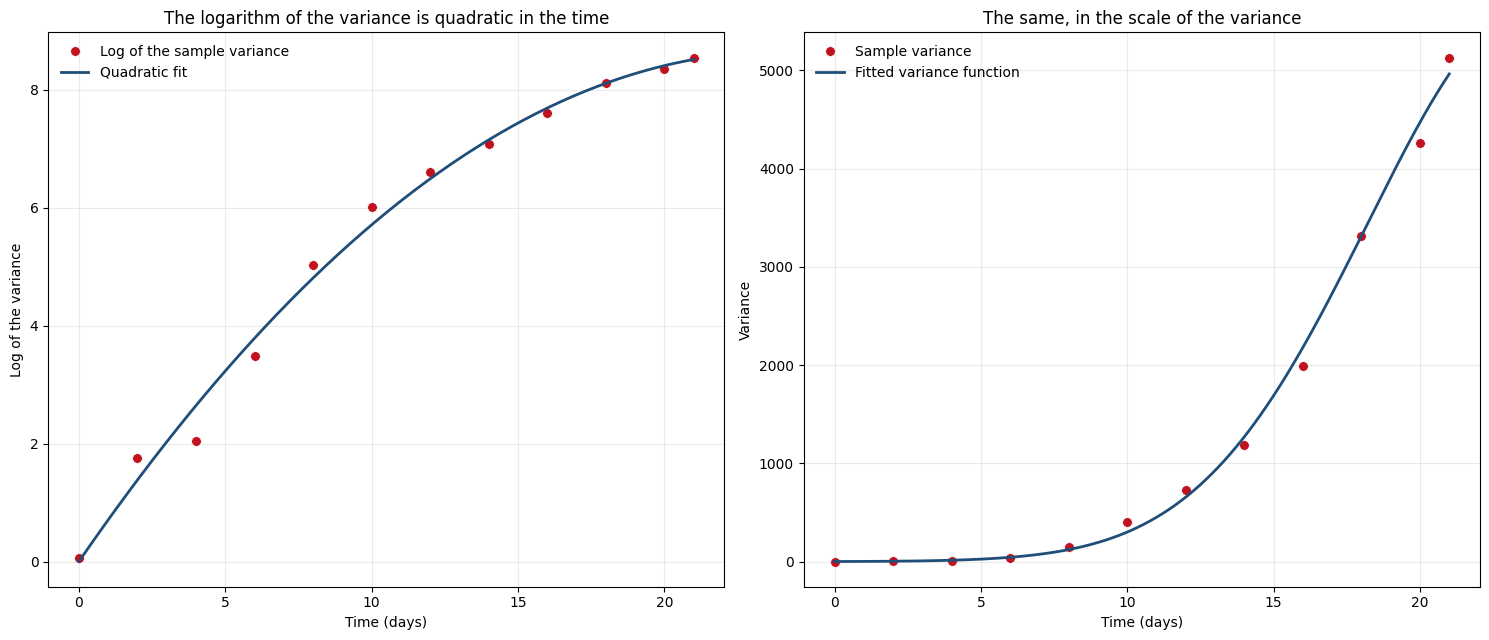

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

axes[0].plot(times, y_var, 'o', color=point_color, markersize=7, markeredgecolor='white', markeredgewidth=0.5,
             label='Log of the sample variance')
axes[0].plot(x_grid, betas[0]*x_grid + betas[1]*x_grid**2, color=line_color, lw=2, label='Quadratic fit')
axes[0].set_ylabel('Log of the variance')
axes[0].set_title('The logarithm of the variance is quadratic in the time')

axes[1].plot(times, dat_weights_regression['var'], 'o', color=point_color, markersize=7, markeredgecolor='white',
             markeredgewidth=0.5, label='Sample variance')
axes[1].plot(x_grid, np.exp(betas[0]*x_grid + betas[1]*x_grid**2), color=line_color, lw=2, label='Fitted variance function')
axes[1].set_ylabel('Variance')
axes[1].set_title('The same, in the scale of the variance')

for ax in axes:
    ax.set_xlabel('Time (days)')
    ax.legend(loc='upper left', frameon=False)
    ax.grid(True, alpha=0.25)
plt.tight_layout()

### Stabilizing the variance

If we multiply the weights by $w(t) = \exp\left(-\frac{1}{2}(\delta_1t + \delta_2t^2)\right)$ their variance becomes approximately constant.

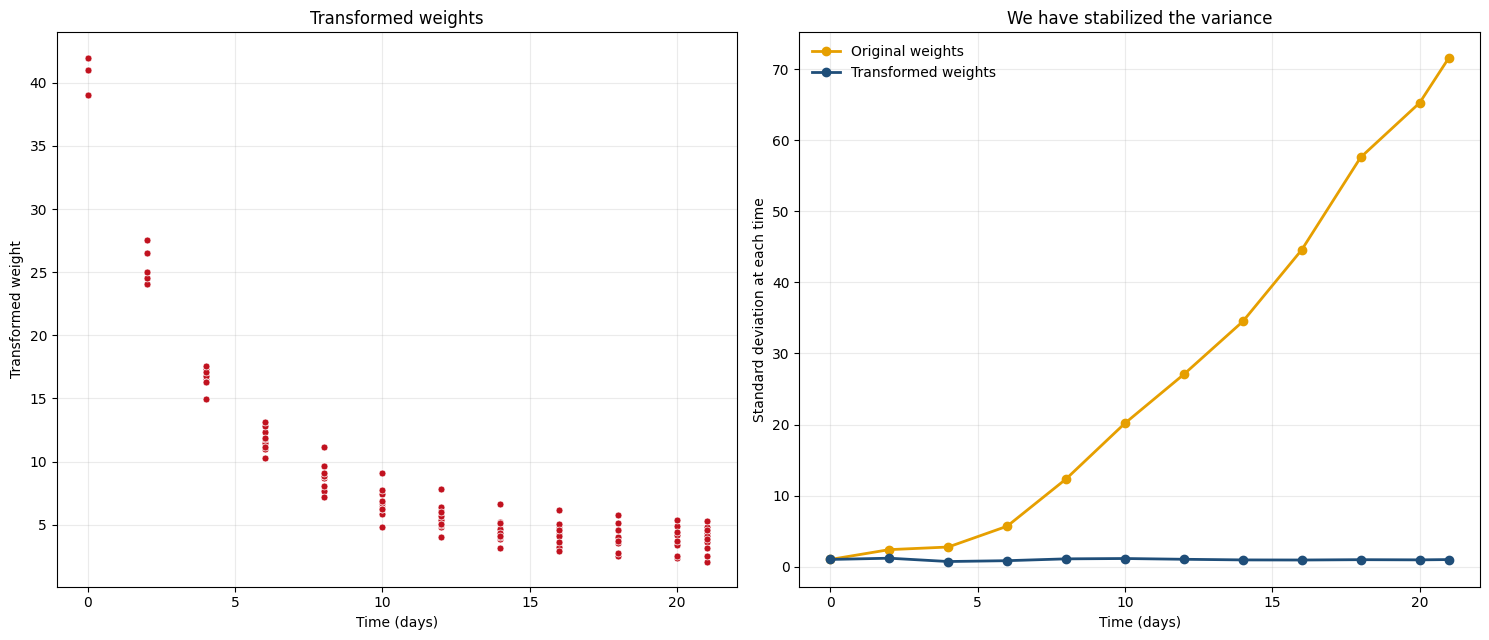

In [11]:
def weight_function(t):
    return np.exp(-0.5*(betas[0]*t+betas[1]*t**2))

Y_transform = Y*weight_function(x)

sd_before = [Y[x == time].std(ddof=1) for time in times]
sd_after = [Y_transform[x == time].std(ddof=1) for time in times]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
axes[0].plot(x, Y_transform, 'o', color=point_color, markersize=5, markeredgecolor='white', markeredgewidth=0.5)
axes[0].set_ylabel('Transformed weight')
axes[0].set_title('Transformed weights')

axes[1].plot(times, sd_before, 'o-', color='#E69F00', lw=2, label='Original weights')
axes[1].plot(times, sd_after, 'o-', color=line_color, lw=2, label='Transformed weights')
axes[1].set_ylabel('Standard deviation at each time')
axes[1].set_title('We have stabilized the variance')
axes[1].legend(loc='upper left', frameon=False)
for ax in axes:
    ax.set_xlabel('Time (days)')
    ax.grid(True, alpha=0.25)
plt.tight_layout()

## Weighted nonlinear least squares

We fit the transformed model $w(t)\,y = w(t)\,f(t;\theta) + \varepsilon$, which has constant variance.

In [12]:
def logistic_gowth_transform(theta, t):
    return weight_function(t) * logistic_gowth(theta, t)

def fun(theta):
    return logistic_gowth_transform(theta, x) - Y_transform

log_growth_transform = least_squares(fun, theta0)
theta_star_transform = log_growth_transform.x
F_matrix = log_growth_transform.jac

hat_sigma2_transform = sum((log_growth_transform.fun)**2)/(n-p)
var_matrix_params_transform = hat_sigma2_transform * np.linalg.inv(F_matrix.T @ F_matrix)

print('sigma^2:', hat_sigma2_transform)
summary(theta_star_transform, var_matrix_params_transform, n-p)

sigma^2: 0.9711419043568953


,estimate,std. error,t,p-value,lower,upper
M,568.0818,114.8741,4.9453,0.0,340.5796,795.5840
r,0.1203,0.0051,23.5585,0.0,0.1102,0.1305
b,21.2925,2.6331,8.0866,0.0,16.0779,26.5071


The observations of the first days, which are very precise, now count more, and the noisy last days count less. The standard errors of $r$ and $b$ are much smaller. The maximum weight $M$ changes a lot and stays very uncertain: the chicks were not observed long enough to see where the growth stops.

In [13]:
pd.DataFrame({'ordinary': theta_star, 'weighted': theta_star_transform,
              'std. error ordinary': np.sqrt(np.diag(var_matrix_params)),
              'std. error weighted': np.sqrt(np.diag(var_matrix_params_transform))}, index=['M', 'r', 'b']).round(4)

,ordinary,weighted,std. error ordinary,std. error weighted
M,466.1356,568.0818,130.1502,114.8741
r,0.1295,0.1203,0.0217,0.0051
b,18.3364,21.2925,4.3881,2.6331


## The result

The variance of a new observation at time $t$ is now $\hat\sigma^2\exp(\delta_1t + \delta_2t^2)$ plus the variance of the fitted curve.

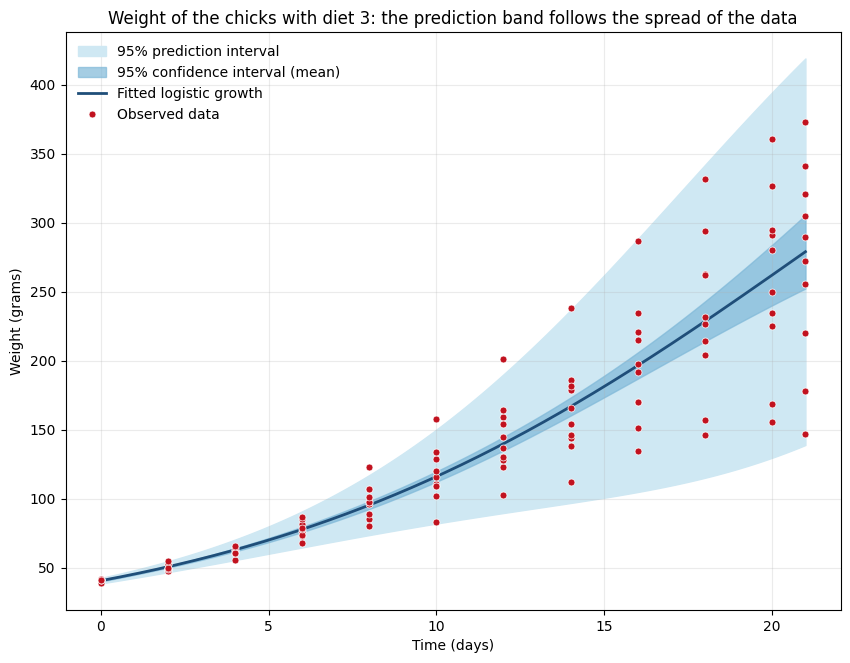

In [14]:
def plot_result(ax, t_max, title):
    X0 = np.linspace(0, t_max, 300)
    y_hat = logistic_gowth(theta_star_transform, X0)
    F_0 = gradient(X0, theta_star_transform)

    sist_var = np.sum((F_0 @ var_matrix_params_transform) * F_0, axis=1)
    erro_var = hat_sigma2_transform*np.exp(betas[0]*X0+betas[1]*X0**2)

    ax.fill_between(X0, y_hat - q_t*np.sqrt(sist_var+erro_var), y_hat + q_t*np.sqrt(sist_var+erro_var),
                    color=pi_color, label=pi_label)
    ax.fill_between(X0, y_hat - q_t*np.sqrt(sist_var), y_hat + q_t*np.sqrt(sist_var), color=ci_color, alpha=0.7,
                    label=ci_label)
    ax.plot(X0, y_hat, color=line_color, lw=2, label='Fitted logistic growth')
    plot_chicks(ax, lines=False)
    ax.set_title(title)
    ax.legend(loc='upper left', frameon=False)

fig, ax = plt.subplots(figsize=(10, 7.5))
plot_result(ax, 21, 'Weight of the chicks with diet 3: the prediction band follows the spread of the data')

### Extrapolating

Beyond the last observation we extrapolate two models at once, the growth curve and the variance function. The quadratic for the log-variance has a maximum, after which the fitted variance decreases: the prediction band outside the observed range should not be trusted.

Time at which the fitted variance function is maximum: 23.96965210543838


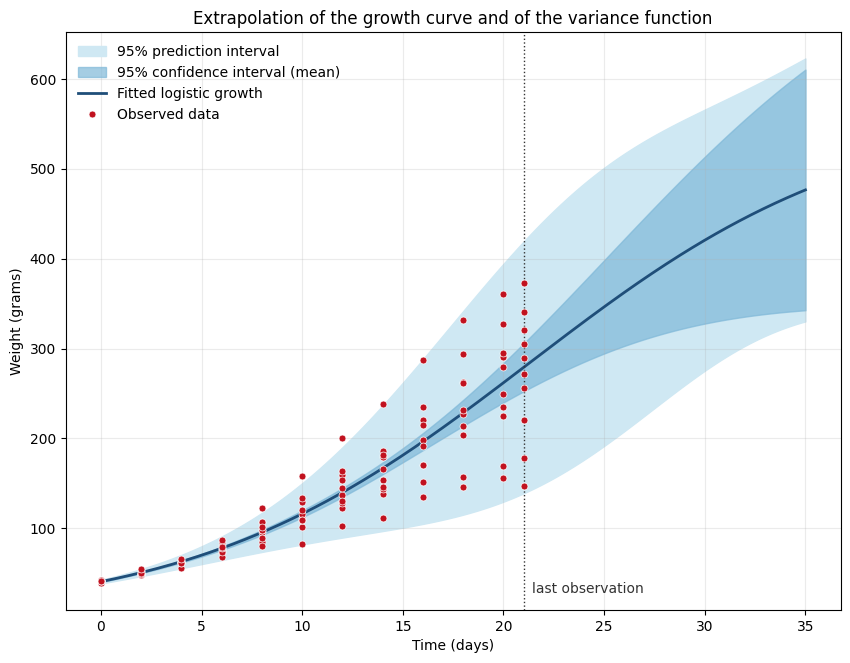

In [15]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_result(ax, 35, 'Extrapolation of the growth curve and of the variance function')
ax.axvline(21, ls=':', color='#333333', lw=1)
ax.annotate('last observation', (21, 0.03), xycoords=('data', 'axes fraction'), xytext=(6, 0),
            textcoords='offset points', fontsize=10, color='#333333')
print('Time at which the fitted variance function is maximum:', -betas[0]/(2*betas[1]))